# 12b — Khoang phân cụm (M10), đợt 2: hiểu kết quả phân cụm thừa

**Mục đích.** Hiểu kết quả PL-E01 và PL-E01b trước khi thiết kế bước gộp (PL-E02):
- kết quả chính thức thay đổi thế nào theo K';
- bên trong một cách chia K' = 20 trên cấu hình paper: các mảnh của silk và cụm của lớp hiếm;
- cách đo "hai cụm có nên gộp không" bằng khoảng cách Bhattacharyya (paper, Eq. 9), học trên dữ liệu đồ chơi.

**Phạm vi.**
- Bối cảnh chính: cấu hình paper (`ft`); `fz` là bối cảnh phụ (PL-QD4).
- Được phép xem K' > 5 trên pool GC10, vì PL-E01 và PL-E01b đã chạy chính thức.
- Gộp cụm trên dữ liệu thật chỉ làm sau khi tiền đăng ký PL-E02; ở đây chỉ gộp trên dữ liệu đồ chơi.
- Số chính thức đọc thẳng từ `metrics.json` của các run; notebook không tính lại.

In [2]:
# cell 2: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes")),
      "| features", Path("runs/inputs.txt").read_text().strip())


commit 37db095 | code dirty False | features features/20261005_013042__gc10_fz_cls5first_img80pct/dino-vitb16


## Kết quả chính thức theo K'

Mỗi run (PL-E01: `fz`, 10 seed; PL-E01b: `ft`, 3 FT seed × 10 seed) ghi vào `metrics.json` số liệu cho mọi K' ∈ {5, 10, 15, 20, 30}. Hình vẽ, cho rolled_pit và crease, số ảnh của lớp nằm trong cụm tốt nhất mà lớp đó sở hữu: chấm nhỏ là từng seed, đường là trung bình 10 seed. Đường ngang là ngưỡng 50% (rolled 9/17, crease 16/32); đường chấm dọc là K' = 20, nơi chốt quyết định. Các K' khác chỉ để mô tả.

Đọc hình: chấm nằm trên đường ngang nghĩa là ở seed đó lớp có cụm riêng chứa ít nhất một nửa số ảnh của nó.

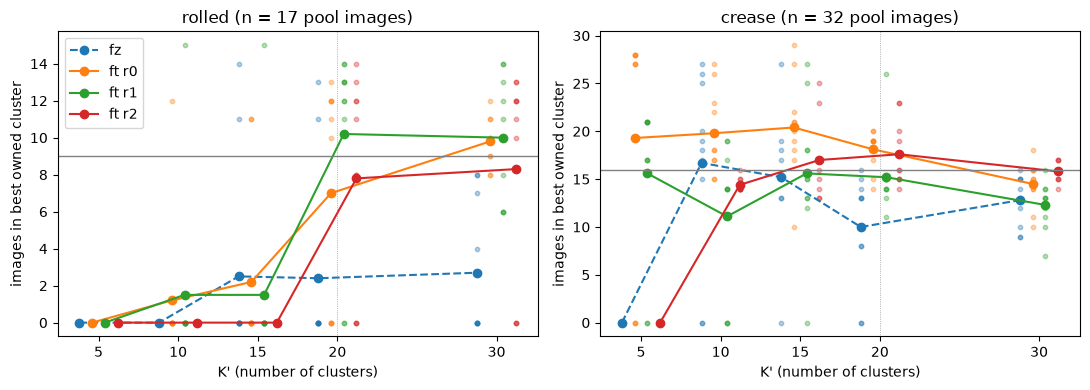

In [3]:
# cell 4 - official results: images of each rare class in its best owned cluster vs K' (from runs/*/metrics.json)
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

N = {"rolled": 17, "crease": 32}
KS = [5, 10, 15, 20, 30]
GROUPS = {"fz": "gc10_pl01", "ft r0": "gc10_pl01b_r0", "ft r1": "gc10_pl01b_r1", "ft r2": "gc10_pl01b_r2"}
OFF = dict(zip(GROUPS, [-1.2, -0.4, 0.4, 1.2]))                     # small x shifts so the groups do not overlap
M = {rd.name.split("__", 1)[1]: json.loads((rd / "metrics.json").read_text()) for rd in Path("runs").glob("*__gc10_pl01*")}
assert len(M) == 40, len(M)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (c, n) in zip(axes, N.items()):
    for g, prefix in GROUPS.items():
        imgs = np.array([[M[f"{prefix}_s{s}"][f"k{k}_best_{c}"] * n for k in KS] for s in range(10)])   # seeds x K'
        x = np.array(KS) + OFF[g]
        line, = ax.plot(x, imgs.mean(0), marker="o", ls="--" if g == "fz" else "-", label=g)
        ax.scatter(np.repeat(x, 10), imgs.T.ravel(), s=10, alpha=0.35, color=line.get_color())
    ax.axhline(np.ceil(n / 2), color="gray", lw=1)
    ax.axvline(20, color="gray", lw=0.5, ls=":")
    ax.set(title=f"{c} (n = {n} pool images)", xlabel="K' (number of clusters)", xticks=KS,
           ylabel="images in best owned cluster")
axes[0].legend()
fig.tight_layout()
plt.show()

## Mổ một cách chia 20 nhóm (cấu hình paper)

Lấy `ft` r0, seed 4: cùng đặc trưng và seed với notebook 04, nên so được với cách chia 5 nhóm ở đó (khi đó rolled và crease không có cụm riêng). Ở run chính thức của PL-E01b, seed này đạt cả hai lớp (rolled 12/17, crease 20/32).

Cell dưới phát lại pipeline tới M10, chụp trạng thái RNG, rồi chia lại với K' = 20 từ đúng trạng thái đó; kết quả phải trùng run chính thức. Mỗi dòng của bảng là một cụm: cỡ, lớp sở hữu, độ thuần, ba lớp đông nhất. Hai dòng cuối cho biết ảnh của rolled và crease rải vào những cụm nào.

Đọc bảng:
- silk sở hữu bao nhiêu cụm: đó là các mảnh cần gộp lại.
- cụm của rolled và crease lẫn với lớp nào: đó là lớp mà bước gộp dễ nuốt nhầm.
- có cụm nào do lớp cũ sở hữu không.

In [4]:
# cell 6 - inside one K' = 20 partition on the paper setting (ft r0, seed 4; same features and seed as notebook 04)
import contextlib, io
import pandas as pd
from pl_cluster import _capture, score
from clustering.kmeans import KMeansCluster

SEED, FT = 4, "gc10_ft_cls5first_img80pct_r0"
FEATURES = sorted(Path("features").glob(f"*__{FT}"))[0] / "dino-vitb16-sl"
buf = io.StringIO()
with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
    r, state = _capture(SEED, FEATURES)                          # replay up to M10 + RNG state at fit entry (~1 min)
st, args = r["stages"][1], r["args"]
X, y = st["train"]._x, np.asarray(st["train"]._y).astype(int)
NAMES = [c.split("_")[0] for c in json.load(open("splits/gc10_split.json"))["classes"]]

np.random.set_state(state)                                        # same start as the official run
cl = KMeansCluster(num_classes=20, label_offset=args.base, n_init=args.kmeans_n_init)
cl.fit(X)
ids = np.asarray(cl.predict_raw(X))
sc = score(y, ids, NAMES, n_old=args.base)
ref = M[f"gc10_pl01b_r0_s{SEED}"]                                # metrics.json of the official run
assert all(np.isclose(sc[k], ref[f"k20_{k}"]) for k in sc), "differs from the official run"

rows = []
for k in range(20):
    counts = np.bincount(y[ids == k], minlength=len(NAMES))
    top = np.argsort(-counts)[:3]
    rows.append({"cluster": k, "size": int(counts.sum()), "owner": NAMES[top[0]],
                 "purity": round(counts[top[0]] / counts.sum(), 2),
                 "top 3": ", ".join(f"{NAMES[c]} {counts[c]}" for c in top if counts[c] > 0)})
tab = pd.DataFrame(rows).sort_values(["owner", "size"], ascending=[True, False])
print(tab.to_string(index=False))
for c in ("rolled", "crease"):
    ci = NAMES.index(c)
    where = np.bincount(ids[y == ci], minlength=20)
    print(f"{c}: " + ", ".join(f"cluster {k}: {where[k]}" for k in np.argsort(-where) if where[k] > 0))

 cluster  size     owner  purity                              top 3
      13    27    crease    0.74     crease 20, welding 4, rolled 2
       0    12  crescent    0.75     crescent 9, welding 2, waist 1
       6    52 inclusion    0.52    inclusion 27, silk 13, water 10
      16    48 inclusion    0.52    inclusion 25, silk 22, crease 1
       1    42 inclusion    0.74              inclusion 31, silk 11
      17    32 inclusion    0.97                inclusion 31, oil 1
      15    14       oil    0.64       oil 9, inclusion 3, rolled 2
       3    15  punching    0.67 punching 10, welding 4, crescent 1
      11    23    rolled    0.52    rolled 12, waist 6, inclusion 3
       2   105      silk    0.99              silk 104, inclusion 1
       8    67      silk    0.99               silk 66, inclusion 1
      19    58      silk    0.98               silk 57, inclusion 1
       5    50      silk    1.00                            silk 50
      18    40      silk    0.75              si

## Học — khoảng cách Bhattacharyya: khi nào hai cụm nên gộp

**Định nghĩa** (Bhattacharyya 1943; công thức như paper, Eq. 9). Mô tả mỗi cụm bằng một Gaussian $N(\mu_1, \Sigma_1)$, $N(\mu_2, \Sigma_2)$. Đặt $\Sigma = (\Sigma_1 + \Sigma_2)/2$:
$D_B = \tfrac{1}{8}(\mu_1 - \mu_2)^\top \Sigma^{-1} (\mu_1 - \mu_2) + \tfrac{1}{2} \ln \dfrac{\det \Sigma}{\sqrt{\det \Sigma_1 \det \Sigma_2}}$.
Số hạng đầu đo khoảng cách giữa hai tâm, tính theo độ trải chung. Số hạng sau đo độ khác nhau về hình dạng. Hệ số chồng lấn (overlap) $BC = e^{-D_B}$ nằm trong (0, 1]. Với hai lớp có xác suất như nhau, sai số Bayes không vượt quá $BC/2$ (cận Bhattacharyya; Fukunaga 1990).

**Ví dụ.** $N(0, 1)$ và $N(3, 1)$: $D_B = 9/8 = 1.125$, $BC = 0.32$, nên sai số Bayes $\le 0.16$ (giá trị thật: 0.067).

**Ý tưởng gộp:** hai cụm có $D_B$ nhỏ (chồng lấn nhiều) thì gộp; $D_B$ lớn thì giữ riêng. Cell dưới so ba cặp trên dữ liệu 1 chiều:
- hai mảnh của cùng một lớp (nhóm lớn bị chẻ đôi);
- nhóm nhỏ sạch so với mảnh gần nhất;
- nhóm nhỏ bị lẫn 6 điểm của lớp bên cạnh (giống cụm của rolled, có 6 ảnh waist) so với mảnh gần nhất.

**Cảnh báo cho dữ liệu thật:** cụm của lớp hiếm chỉ có 12–30 ảnh, trong khi không gian có 64 hoặc 768 chiều. Ước lượng $\Sigma$ khi số ảnh nhỏ hơn số chiều là bài toán suy biến (D21), nên phải co (shrinkage) hoặc dùng covariance chéo. Cách ước lượng $\Sigma$ là một lựa chọn thiết kế của PL-E02.

In [5]:
# cell 8 - toy (1-D): Bhattacharyya distance between a fragment of the big group and its neighbours
def bhattacharyya(m1, v1, m2, v2):
    v = (v1 + v2) / 2
    return (m1 - m2) ** 2 / (8 * v) + 0.5 * np.log(v / np.sqrt(v1 * v2))

def gauss(x):
    return x.mean(), x.var()

rng = np.random.default_rng(0)
big = rng.normal(0, 1, 400)
small = rng.normal(4, 0.1, 15)
mixed = np.concatenate([small, rng.normal(2.0, 0.3, 6)])          # like rolled's cluster: 15 own + 6 from a neighbour
left, right = big[big < 0], big[big >= 0]                          # two fragments of the same class
pairs = {"fragment vs fragment (same class)": (left, right),
         "clean small group vs nearest fragment": (small, right),
         "mixed small group vs nearest fragment": (mixed, right)}
for name, (a, b) in pairs.items():
    d = bhattacharyya(*gauss(a), *gauss(b))
    print(f"{name:40s} D_B = {d:6.2f} | overlap BC = exp(-D_B) = {np.exp(-d):.3f}")

fragment vs fragment (same class)        D_B =   0.90 | overlap BC = exp(-D_B) = 0.405
clean small group vs nearest fragment    D_B =   7.47 | overlap BC = exp(-D_B) = 0.001
mixed small group vs nearest fragment    D_B =   1.49 | overlap BC = exp(-D_B) = 0.226
